
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/09_Lab_Hopfield.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio: Memorias asociativas con redes de Hopfield

## Objetivo

Construir una red de Hopfield capaz de almacenar imágenes binarias y recuperar una imagen original a partir de una versión con ruido.


# Actividades

Para las imágenes dadas, construya un algoritmo que permita recuperar la imagen original a partir de una imagen perturbada.

Debe implementar funciones para:

1. Convertir una imagen binaria en un vector de estados.
2. Calcular la matriz de pesos de Hopfield.
3. Calcular el campo local que siente una neurona.
4. Actualizar el estado de una neurona.
5. Calcular la energía total de la red.
6. Aplicar ruido a una imagen.
7. Recuperar la imagen mediante actualización asincrónica aleatoria.

---

# Modelo de Hopfield

La matriz de pesos se define mediante la regla de Hebb:

$$
w_{ij}=\frac{1}{N}\sum_{\mu=1}^{P}\xi_i^\mu \xi_j^\mu
$$

con:

$$
w_{ii}=0
$$

donde:

- $N$ es el número total de píxeles,
- $P$ es el número de patrones almacenados,
- $\xi^\mu$ es el patrón $\mu$-ésimo.

---

# Campo local

Para una neurona $i$, el campo local es:

$$
h_i=\sum_j w_{ij}s_j
$$

Este campo representa la influencia colectiva que todas las demás neuronas ejercen sobre la neurona $i$.

---

# Regla de actualización

La actualización determinista de Hopfield es:

$$
s_i \leftarrow \mathrm{sign}(h_i)
$$

Si:

$$
h_i>0
$$

entonces:

$$
s_i=1
$$

Si:

$$
h_i<0
$$

entonces:

$$
s_i=-1
$$

---

# Energía de la red

La energía total del sistema se define como:

$$
E(s)=-\frac{1}{2}\sum_{ij}w_{ij}s_is_j
$$

o equivalentemente:

$$
E(s)=-\frac{1}{2}s^TWs
$$

El proceso de recuperación debe tender a disminuir la energía.

---

# Algoritmo sugerido

Dada una imagen con ruido:

1. Seleccione aleatoriamente un píxel $i$.
2. Calcule el campo local:

$$
h_i=\sum_j w_{ij}s_j
$$

3. Actualice el estado del píxel:

$$
s_i \leftarrow \mathrm{sign}(h_i)
$$

4. Calcule la nueva energía del sistema:

$$
E(s)=-\frac{1}{2}s^TWs
$$

5. Visite otro píxel aleatoriamente.
6. Repita el proceso hasta que:
   - la imagen deje de cambiar,
   - la energía se estabilice,
   - o se alcance un número máximo de iteraciones.


# Comentario importante

La actualización debe ser preferiblemente **asincrónica y aleatoria**, porque cada vez que se actualiza un píxel, cambia el estado global de la red. Por tanto, el siguiente campo local debe calcularse usando la imagen ya actualizada.

---

# Preguntas guía

1. ¿La energía disminuye durante la recuperación?
2. ¿La red recupera exactamente la imagen original?
3. ¿Qué ocurre si aumenta el nivel de ruido?
4. ¿Qué pasa si se almacenan varias imágenes?
5. ¿Aparecen estados espurios?
6. ¿La recuperación depende del orden en que se actualizan los píxeles?
7. ¿Qué diferencia hay entre actualización sincrónica y asincrónica?

---

# Capacidad de memoria

La capacidad aproximada de una red de Hopfield clásica es:

$$
P_c \approx 0.138N
$$

donde:

- $P_c$ es el número máximo de patrones recuperables,
- $N$ es el número total de neuronas.

Cuando el número de patrones almacenados supera este valor, aparecen errores y estados espurios.




In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
def patrones_balanceados(n, m):
    horizontal = -np.ones((n, m))
    horizontal[:n//2, :] = 1

    vertical = -np.ones((n, m))
    vertical[:, :m//2] = 1

    checker = np.indices((n, m)).sum(axis=0)
    checker = np.where(checker % 2 == 0, 1, -1)

    return horizontal, vertical, checker

def agregar_ruido(s, frac=0.25, seed=None):
    if seed is not None:
        np.random.seed(seed)

    s_ruido = s.copy()
    N = len(s)

    n_flip = int(frac * N)
    idx = np.random.choice(N, n_flip, replace=False)

    s_ruido[idx] *= -1

    return s_ruido

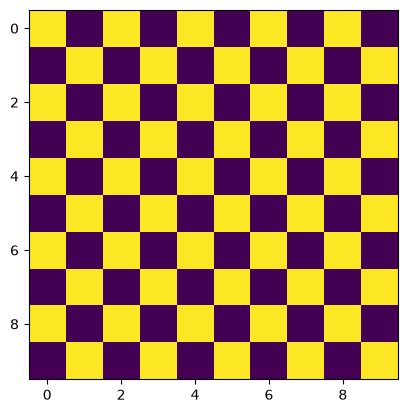

In [3]:
h, v, d = patrones_balanceados(10, 10)
plt.imshow(d)

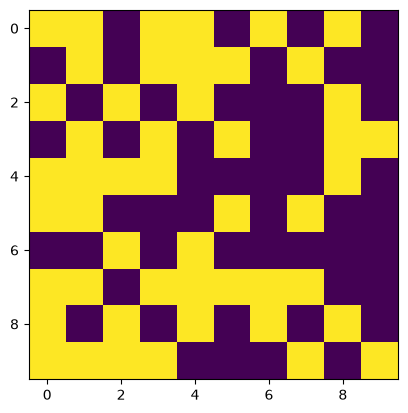

In [4]:
s_ruido = agregar_ruido(np.concat(d), frac=0.25, seed=10)
plt.imshow(np.reshape(s_ruido, (10, 10)))

Solapamientos entre patrones (ortogonales si ≈ 0):
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


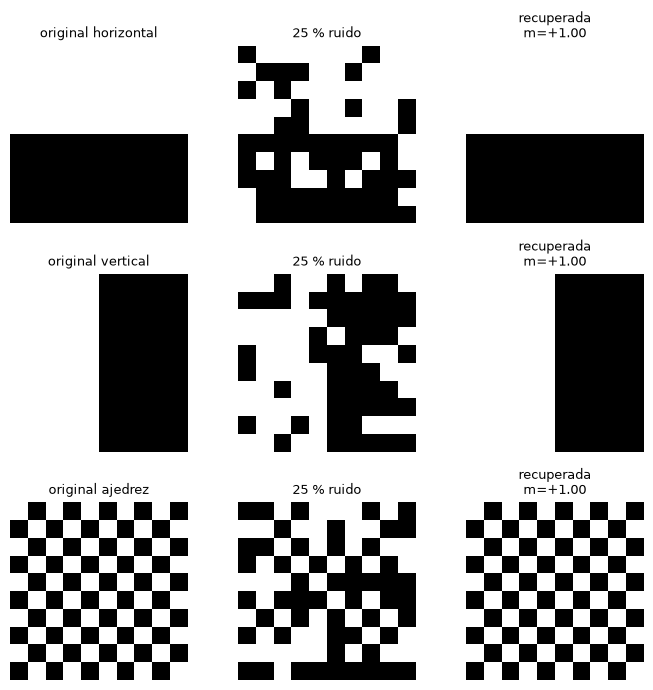

In [5]:
# ============================================================
# Funciones de la red de Hopfield
# ============================================================

def imagen_a_vector(img):
    """1. Imagen binaria (n x m) con valores {-1,+1} (o {0,1}) -> vector de estados de longitud N = n*m."""
    img = np.asarray(img)
    if set(np.unique(img)) <= {0, 1}:          # si viene en {0,1}, la pasamos a {-1,+1}
        img = 2 * img - 1
    return img.astype(np.int8).ravel()

def vector_a_imagen(s, n, m):
    return np.asarray(s).reshape(n, m)

def matriz_pesos(patrones):
    """2. Regla de Hebb: w_ij = (1/N) sum_mu xi_i^mu xi_j^mu, con w_ii = 0.
    patrones: arreglo (P, N) o lista de vectores."""
    Xi = np.atleast_2d(np.asarray(patrones, dtype=np.float32))
    P, N = Xi.shape
    W = (Xi.T @ Xi) / N
    np.fill_diagonal(W, 0.0)
    return W

def campo_local(W, s, i):
    """3. h_i = sum_j w_ij s_j"""
    return float(W[i] @ s)

def actualizar_neurona(W, s, i):
    """4. s_i <- sign(h_i). Si h_i = 0 se conserva el estado. Modifica s en el sitio.
    Devuelve (cambio de estado, campo local)."""
    h = campo_local(W, s, i)
    nuevo = 1 if h > 0 else (-1 if h < 0 else s[i])
    cambio = nuevo - s[i]
    s[i] = nuevo
    return cambio, h

def energia(W, s):
    """5. E(s) = -1/2 s^T W s"""
    s = s.astype(np.float32)
    return float(-0.5 * s @ W @ s)

def agregar_ruido(s, frac=0.25, seed=None):
    """6. Voltea una fracción frac de los píxeles elegidos al azar."""
    rng = np.random.default_rng(seed)
    s_ruido = np.array(s, copy=True)
    idx = rng.choice(len(s), int(frac * len(s)), replace=False)
    s_ruido[idx] *= -1
    return s_ruido

def recuperar(W, s0, max_barridos=50, seed=None, guardar_cada=None):
    """7. Actualización asincrónica aleatoria.
    En cada barrido se visitan los N píxeles en un orden aleatorio nuevo; cada actualización
    usa el estado ya actualizado. Se detiene cuando un barrido completo no cambia ningún píxel.
    La energía se actualiza de forma incremental: si s_i cambia en Δs_i, ΔE = -Δs_i h_i (porque w_ii = 0).
    Devuelve (estado final, energía por actualización, energía al final de cada barrido, barridos)."""
    rng = np.random.default_rng(seed)
    s = np.array(s0, copy=True).astype(np.int8)
    N = len(s)
    E = energia(W, s)
    E_pasos, E_barridos, estados = [E], [E], [s.copy()]
    for barrido in range(1, max_barridos + 1):
        cambios = 0
        for i in rng.permutation(N):
            ds, h = actualizar_neurona(W, s, i)
            if ds != 0:
                cambios += 1
                E += -ds * h
            E_pasos.append(E)
        E_barridos.append(E)
        if guardar_cada and barrido % guardar_cada == 0:
            estados.append(s.copy())
        if cambios == 0:
            break
    return s, np.array(E_pasos), np.array(E_barridos), barrido

def recuperar_sincronica(W, s0, max_pasos=50):
    """Para comparar: todas las neuronas se actualizan a la vez, s <- sign(W s)."""
    s = np.array(s0, copy=True).astype(np.int8)
    hist = [s.copy()]
    for _ in range(max_pasos):
        h = W @ s
        s = np.where(h > 0, 1, np.where(h < 0, -1, s)).astype(np.int8)
        hist.append(s.copy())
        if np.array_equal(hist[-1], hist[-2]):
            break
    return s, hist

def solapamiento(a, b):
    """m = (1/N) a·b : 1 = idénticas, -1 = invertidas, 0 = sin relación."""
    return float(np.dot(a.astype(float), b.astype(float)) / len(a))

# --- Prueba con los tres patrones 10x10 ---
patrones_10 = [imagen_a_vector(p) for p in (h, v, d)]
W10 = matriz_pesos(patrones_10)
print("Solapamientos entre patrones (ortogonales si ≈ 0):")
print(np.round(np.array([[solapamiento(a, b) for b in patrones_10] for a in patrones_10]), 2))

fig, ax = plt.subplots(3, 3, figsize=(7, 7))
for k, (xi, nombre) in enumerate(zip(patrones_10, ["horizontal", "vertical", "ajedrez"])):
    sr = agregar_ruido(xi, 0.25, seed=10 + k)
    sf, _, Eb, nb_ = recuperar(W10, sr, seed=k)
    for j, (img_, t) in enumerate([(xi, f"original {nombre}"), (sr, "25 % ruido"),
                                   (sf, f"recuperada\nm={solapamiento(sf, xi):+.2f}")]):
        ax[k, j].imshow(img_.reshape(10, 10), cmap="gray", vmin=-1, vmax=1); ax[k, j].set_title(t, fontsize=9); ax[k, j].axis("off")
plt.tight_layout(); plt.show()


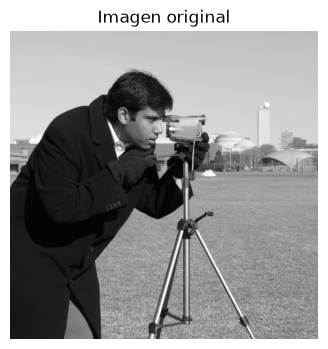

In [6]:
import numpy as np
import matplotlib.pyplot as plt

from skimage import data
from skimage.transform import resize
from skimage.color import rgb2gray

img = data.camera()   # imagen 512x512 en escala de grises

plt.figure(figsize=(4,4))
plt.imshow(img, cmap="gray")
plt.title("Imagen original")
plt.axis("off")
plt.show()

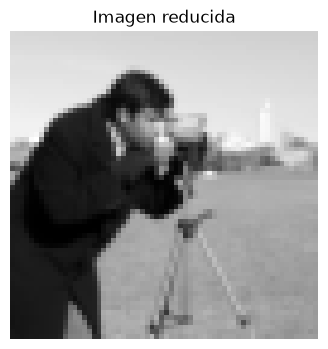

In [7]:
# ============================================================
# Reducir imagen
# ============================================================

n = 64
m = 64

img_small = resize(img, (n, m), anti_aliasing=True)

plt.figure(figsize=(4,4))
plt.imshow(img_small, cmap="gray")
plt.title("Imagen reducida")
plt.axis("off")
plt.show()

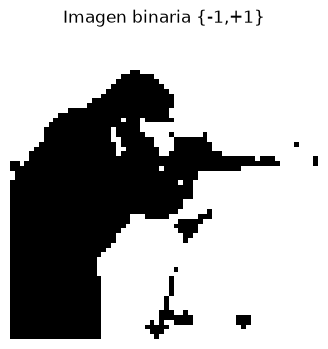

In [8]:
# ============================================================
# Binarización
# ============================================================

threshold = img_small.mean()

img_bin = np.where(img_small > threshold, 1, -1)

plt.figure(figsize=(4,4))
plt.imshow(img_bin, cmap="gray")
plt.title("Imagen binaria {-1,+1}")
plt.axis("off")
plt.show()

In [9]:
img_bin

array([[ 1,  1,  1, ...,  1,  1,  1],
       [ 1,  1,  1, ...,  1,  1,  1],
       [ 1,  1,  1, ...,  1,  1,  1],
       ...,
       [-1, -1, -1, ...,  1,  1,  1],
       [-1, -1, -1, ...,  1,  1,  1],
       [-1, -1, -1, ...,  1,  1,  1]], shape=(64, 64))

In [10]:
# ============================================================
# Ruido
# ============================================================

def agregar_ruido(s, frac=0.30, seed=None):
    if seed is not None:
        np.random.seed(seed)

    s_ruido = s.copy()
    N = len(s)

    n_flip = int(frac * N)
    idx = np.random.choice(N, n_flip, replace=False)

    s_ruido[idx] *= -1

    return s_ruido


frac_ruido = 0.30

s_ruido = agregar_ruido(np.concat(img_bin), frac=frac_ruido, seed=123)


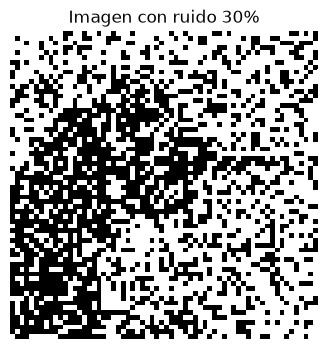

In [11]:
plt.figure(figsize=(4,4))
plt.imshow(s_ruido.reshape(n, m), cmap="gray")
plt.title(f"Imagen con ruido {frac_ruido*100:.0f}%")
plt.axis("off")
plt.show()

N = 4096 neuronas, barridos hasta converger: 2
Energía: ruido = -327.8   final = -2047.5   original = -2047.5
Píxeles distintos al original: 0   solapamiento = +1.0000
¿La energía nunca aumentó? True


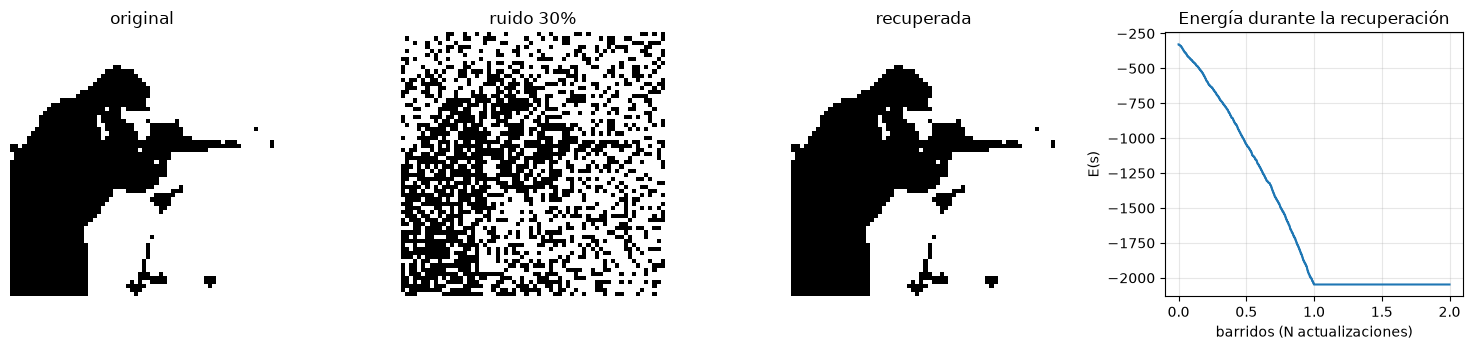

In [12]:
# ============================================================
# Recuperación de la imagen (un solo patrón almacenado)
# ============================================================
xi_cam = imagen_a_vector(img_bin)
N = xi_cam.size
W_cam = matriz_pesos([xi_cam])

s_final, E_pasos, E_barridos, n_barridos = recuperar(W_cam, s_ruido, seed=0)

print(f"N = {N} neuronas, barridos hasta converger: {n_barridos}")
print(f"Energía: ruido = {E_barridos[0]:.1f}   final = {E_barridos[-1]:.1f}   "
      f"original = {energia(W_cam, xi_cam):.1f}")
print(f"Píxeles distintos al original: {np.sum(s_final != xi_cam)}   solapamiento = {solapamiento(s_final, xi_cam):+.4f}")
print(f"¿La energía nunca aumentó? {np.all(np.diff(E_pasos) <= 1e-6)}")

fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
for a, img_, t in zip(ax[:3], [xi_cam, s_ruido, s_final], ["original", f"ruido {frac_ruido:.0%}", "recuperada"]):
    a.imshow(img_.reshape(n, m), cmap="gray", vmin=-1, vmax=1); a.set_title(t); a.axis("off")
ax[3].plot(np.arange(len(E_pasos)) / N, E_pasos)
ax[3].set_xlabel("barridos (N actualizaciones)"); ax[3].set_ylabel("E(s)"); ax[3].set_title("Energía durante la recuperación")
ax[3].grid(alpha=.3)
plt.tight_layout(); plt.show()


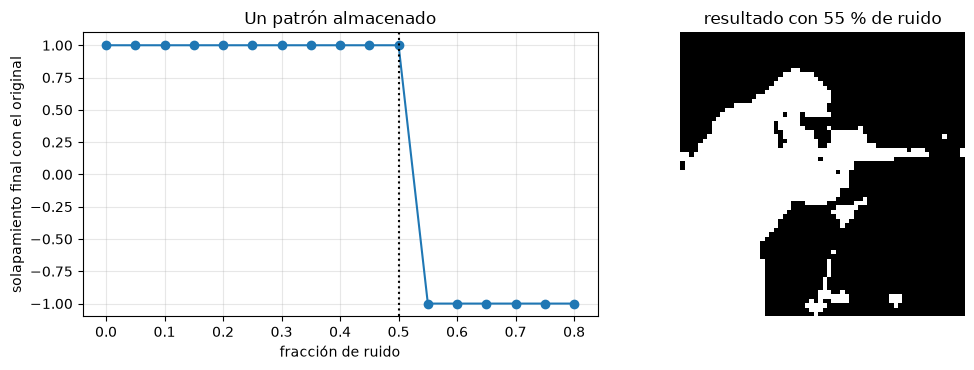

[[ 0.    1.  ]
 [ 0.05  1.  ]
 [ 0.1   1.  ]
 [ 0.15  1.  ]
 [ 0.2   1.  ]
 [ 0.25  1.  ]
 [ 0.3   1.  ]
 [ 0.35  1.  ]
 [ 0.4   1.  ]
 [ 0.45  1.  ]
 [ 0.5   1.  ]
 [ 0.55 -1.  ]
 [ 0.6  -1.  ]
 [ 0.65 -1.  ]
 [ 0.7  -1.  ]
 [ 0.75 -1.  ]
 [ 0.8  -1.  ]]


In [13]:
# ============================================================
# Pregunta 3: ¿qué pasa al aumentar el ruido?  (un patrón)
# ============================================================
fracs = np.arange(0.0, 0.81, 0.05)
m_final = []
for f in fracs:
    sf, *_ = recuperar(W_cam, agregar_ruido(xi_cam, f, seed=1), seed=1)
    m_final.append(solapamiento(sf, xi_cam))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(fracs, m_final, "o-"); ax[0].axvline(0.5, ls=":", color="k")
ax[0].set_xlabel("fracción de ruido"); ax[0].set_ylabel("solapamiento final con el original"); ax[0].grid(alpha=.3)
ax[0].set_title("Un patrón almacenado")
sf55, *_ = recuperar(W_cam, agregar_ruido(xi_cam, 0.55, seed=1), seed=1)
ax[1].imshow(sf55.reshape(n, m), cmap="gray"); ax[1].set_title("resultado con 55 % de ruido"); ax[1].axis("off")
plt.tight_layout(); plt.show()
print(np.round(np.c_[fracs, m_final], 3))


Matriz de solapamientos entre las imágenes:
            cámara  astronauta  monedas  luna  café  gato
cámara        1.00        0.16     0.17  0.25  0.08 -0.07
astronauta    0.16        1.00     0.04  0.20  0.20 -0.04
monedas       0.17        0.04     1.00  0.13  0.04 -0.04
luna          0.25        0.20     0.13  1.00  0.33 -0.06
café          0.08        0.20     0.04  0.33  1.00 -0.07
gato         -0.07       -0.04    -0.04 -0.06 -0.07  1.00


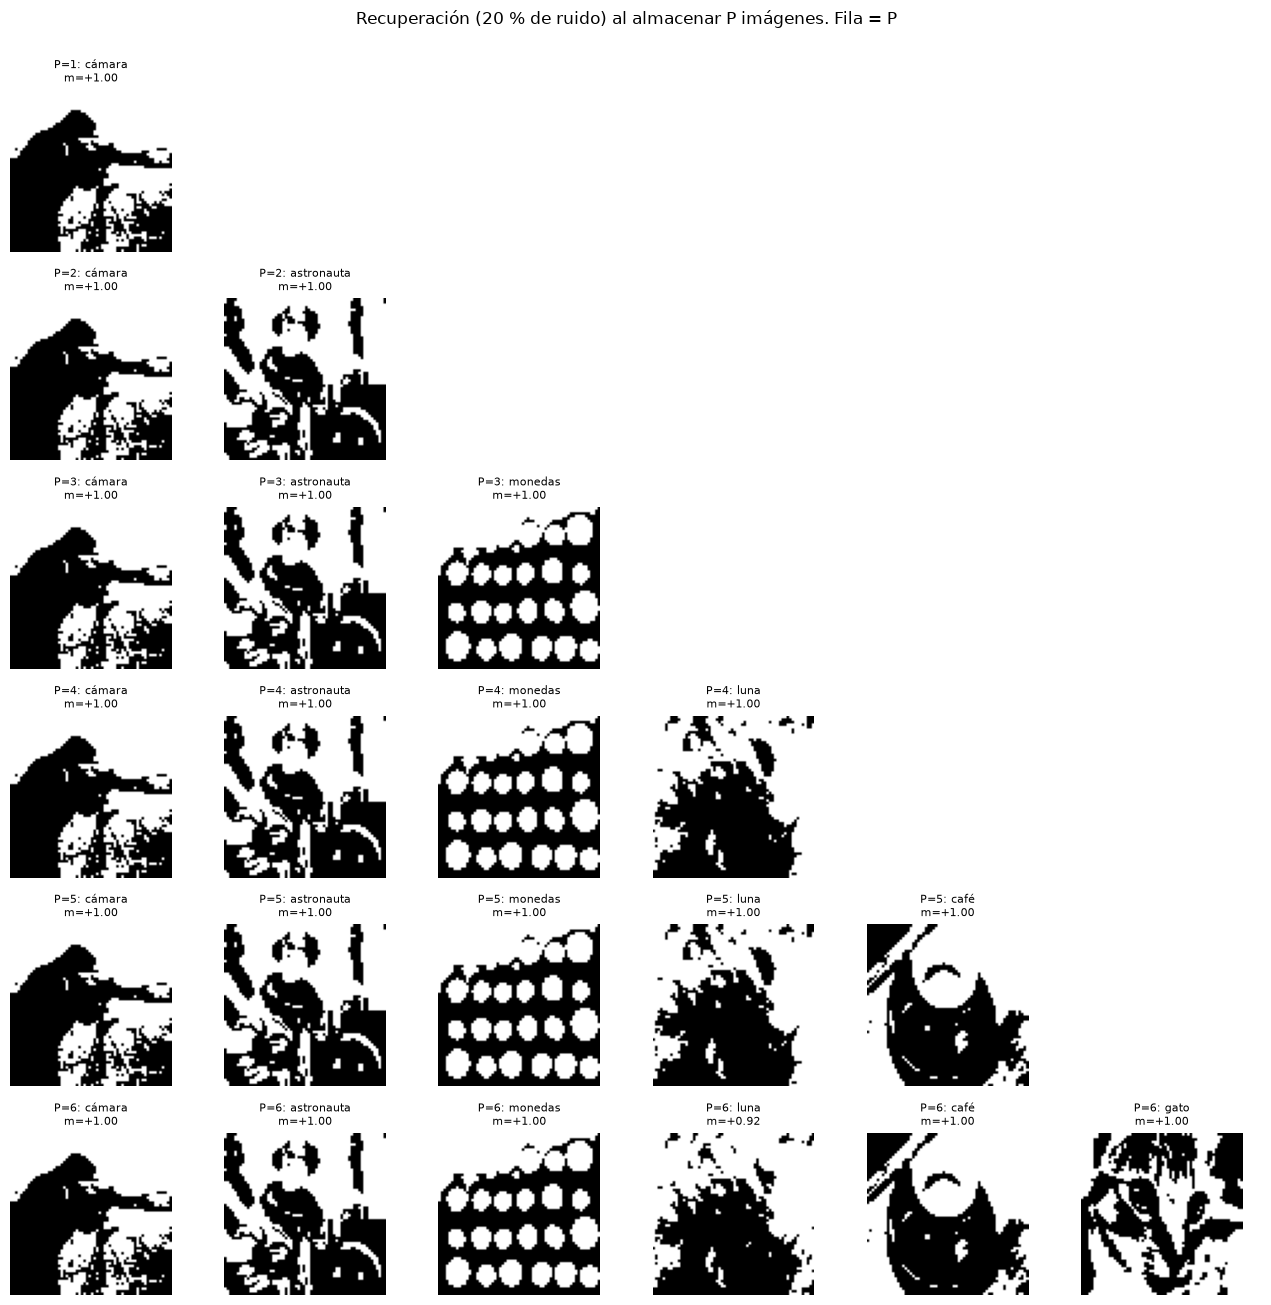

In [14]:
# ============================================================
# Pregunta 4: varias imágenes almacenadas
# ============================================================
from skimage import data as skdata

def binarizar(img_gray, n=64, m=64):
    im = resize(img_gray, (n, m), anti_aliasing=True)
    return np.where(im > np.median(im), 1, -1)          # mediana -> patrones balanceados

imgs = {
    "cámara": data.camera(),
    "astronauta": rgb2gray(skdata.astronaut()),
    "monedas": skdata.coins(),
    "luna": skdata.moon(),
    "café": rgb2gray(skdata.coffee()),
    "gato": rgb2gray(skdata.chelsea()),
}
patrones = {k: imagen_a_vector(binarizar(v)) for k, v in imgs.items()}
nombres = list(patrones)
Xi = np.array([patrones[k] for k in nombres])
print("Matriz de solapamientos entre las imágenes:")
print(pd.DataFrame(Xi.astype(float) @ Xi.T / N, index=nombres, columns=nombres).round(2))

def prueba_P(P, frac=0.2, seed=0):
    W = matriz_pesos(Xi[:P])
    res = []
    for k in range(P):
        sf, *_ = recuperar(W, agregar_ruido(Xi[k], frac, seed=seed + k), seed=seed + k)
        res.append((solapamiento(sf, Xi[k]), sf))
    return res

fig, ax = plt.subplots(len(nombres), len(nombres), figsize=(13, 13))
for P in range(1, len(nombres) + 1):
    res = prueba_P(P)
    for k in range(len(nombres)):
        a = ax[P - 1, k]; a.axis("off")
        if k < P:
            a.imshow(res[k][1].reshape(n, m), cmap="gray", vmin=-1, vmax=1)
            a.set_title(f"P={P}: {nombres[k]}\nm={res[k][0]:+.2f}", fontsize=8)
plt.suptitle("Recuperación (20 % de ruido) al almacenar P imágenes. Fila = P", y=1.0)
plt.tight_layout(); plt.show()


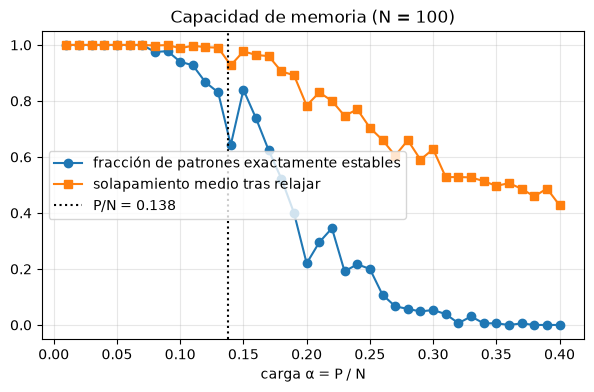

In [15]:
# Capacidad: patrones aleatorios en una red de N = 100 neuronas (10x10)
rng_c = np.random.default_rng(0)
N_c = 100
Ps = np.arange(1, 41)
frac_estables, m_medio = [], []
for P in Ps:
    estables, ms = 0, []
    for rep in range(5):
        Xr = rng_c.choice([-1, 1], size=(P, N_c)).astype(np.int8)
        Wr = matriz_pesos(Xr)
        for k in range(P):
            # ¿el patrón es un punto fijo exacto? y ¿a dónde llega partiendo de él?
            estables += np.all(np.sign(Wr @ Xr[k]) == Xr[k])
            sf, *_ = recuperar(Wr, Xr[k], seed=k)
            ms.append(solapamiento(sf, Xr[k]))
    frac_estables.append(estables / (5 * P)); m_medio.append(np.mean(ms))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(Ps / N_c, frac_estables, "o-", label="fracción de patrones exactamente estables")
ax.plot(Ps / N_c, m_medio, "s-", label="solapamiento medio tras relajar")
ax.axvline(0.138, ls=":", color="k", label="P/N = 0.138")
ax.set_xlabel("carga α = P / N"); ax.legend(); ax.grid(alpha=.3); ax.set_title("Capacidad de memoria (N = 100)")
plt.show()


mezcla de 3 imágenes         -> ¿punto fijo? True   solapamientos finales con (cámara, astronauta, monedas) = [0.64 0.51 0.53]   E = -1951.7
imagen invertida (−cámara)   -> ¿punto fijo? True   solapamientos finales con (cámara, astronauta, monedas) = [-1.   -0.16 -0.17]   E = -2155.6
Energía de los patrones almacenados: [-2155.6, -2099.5, -2108.6]



Destino de 30 estados iniciales aleatorios (3 imágenes almacenadas):
ESPURIO                          10
patrón astronauta (invertido)     7
patrón cámara                     4
patrón cámara (invertido)         3
patrón monedas (invertido)        3
patrón astronauta                 2
patrón monedas                    1
Name: count, dtype: int64


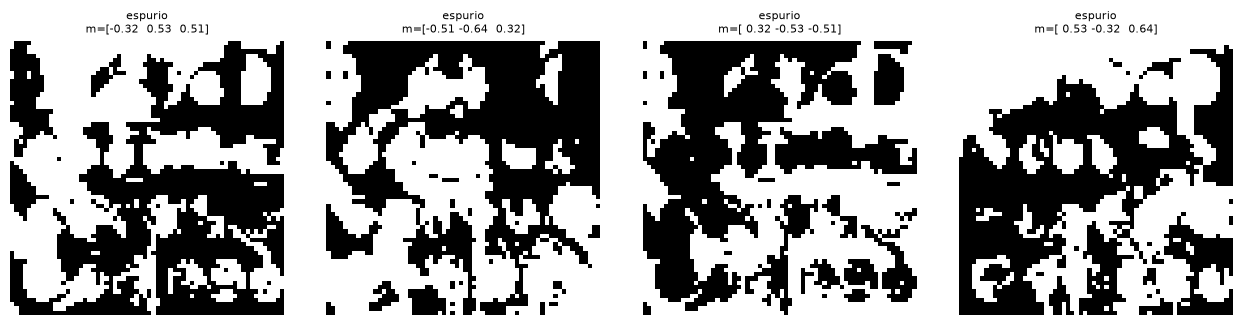

In [16]:
# ============================================================
# Pregunta 5: estados espurios
# ============================================================
W3 = matriz_pesos(Xi[:3])
mezcla = np.sign(Xi[0] + Xi[1] + Xi[2]).astype(np.int8)          # estado mezcla de 3 patrones
inverso = -Xi[0]
for nombre_e, est in [("mezcla de 3 imágenes", mezcla), ("imagen invertida (−cámara)", inverso)]:
    sf, *_ = recuperar(W3, est, seed=0)
    ms = [solapamiento(sf, Xi[k]) for k in range(3)]
    print(f"{nombre_e:28s} -> ¿punto fijo? {np.array_equal(sf, est)}   "
          f"solapamientos finales con (cámara, astronauta, monedas) = {np.round(ms, 2)}   E = {energia(W3, sf):.1f}")
print("Energía de los patrones almacenados:", [round(energia(W3, Xi[k]), 1) for k in range(3)])

# Partiendo de estados completamente aleatorios: ¿a dónde llega la red?
rng_e = np.random.default_rng(3)
finales = []
for rep in range(30):
    sf, *_ = recuperar(W3, rng_e.choice([-1, 1], N).astype(np.int8), seed=rep)
    finales.append(sf)
finales = np.array(finales)
ms = finales.astype(float) @ Xi[:3].T.astype(float) / N
clase = ["patrón " + nombres[np.argmax(np.abs(r))] + (" (invertido)" if r[np.argmax(np.abs(r))] < 0 else "")
         if np.abs(r).max() > 0.95 else "ESPURIO" for r in ms]
print("\nDestino de 30 estados iniciales aleatorios (3 imágenes almacenadas):")
print(pd.Series(clase).value_counts())

i_esp = [k for k, c in enumerate(clase) if c == "ESPURIO"]
if i_esp:
    fig, ax = plt.subplots(1, min(4, len(i_esp)), figsize=(3.2 * min(4, len(i_esp)), 3.2), squeeze=False)
    for a, k in zip(ax[0], i_esp[:4]):
        a.imshow(finales[k].reshape(n, m), cmap="gray"); a.axis("off")
        a.set_title(f"espurio\nm={np.round(ms[k], 2)}", fontsize=8)
    plt.tight_layout(); plt.show()


In [17]:
# ============================================================
# Pregunta 6: ¿depende del orden de actualización?
# ============================================================
def prueba_orden(W_, s0_, ref, n_ordenes=20):
    fin = [recuperar(W_, s0_, seed=sd)[0] for sd in range(n_ordenes)]
    ms_ = [solapamiento(f, ref) for f in fin]
    return len({f.tobytes() for f in fin}), min(ms_), max(ms_)

W4 = matriz_pesos(Xi[:4])
s_ini = agregar_ruido(Xi[0], 0.35, seed=7)
casos_orden = {
    "1 imagen, 30 % ruido": (W_cam, s_ruido, xi_cam),
    "4 imágenes, 35 % ruido": (W4, s_ini, Xi[0]),
}
# Red pequeña cargada: N = 100, P = 8 patrones aleatorios, 40 % de ruido
rng_o = np.random.default_rng(0)
Xr8 = rng_o.choice([-1, 1], size=(8, 100)).astype(np.int8)
casos_orden["N=100, 8 patrones aleatorios, 40 % ruido"] = (matriz_pesos(Xr8), agregar_ruido(Xr8[0], 0.4, seed=3), Xr8[0])

print("Mismo estado inicial, 20 órdenes de actualización aleatorios:")
for nombre_c, (W_, s0_, ref) in casos_orden.items():
    nd, mmin, mmax = prueba_orden(W_, s0_, ref)
    print(f"  {nombre_c:42s} estados finales distintos = {nd:2d}   solapamiento final: min {mmin:+.2f}, max {mmax:+.2f}")


Mismo estado inicial, 20 órdenes de actualización aleatorios:


  1 imagen, 30 % ruido                       estados finales distintos =  1   solapamiento final: min +1.00, max +1.00


  4 imágenes, 35 % ruido                     estados finales distintos =  1   solapamiento final: min +1.00, max +1.00
  N=100, 8 patrones aleatorios, 40 % ruido   estados finales distintos =  4   solapamiento final: min -0.28, max +0.26


In [18]:
# ============================================================
# Pregunta 7: sincrónica vs asincrónica
# ============================================================
casos = {"1 imagen, 30 % ruido": (W_cam, s_ruido, xi_cam),
         "4 imágenes, 35 % ruido": (W4, s_ini, Xi[0])}
for nombre_c, (W_, s0_, ref) in casos.items():
    s_sync, hist = recuperar_sincronica(W_, s0_)
    E_sync = [energia(W_, x) for x in hist]
    ciclo2 = len(hist) > 2 and np.array_equal(hist[-1], hist[-3]) and not np.array_equal(hist[-1], hist[-2])
    s_async, _, E_async, nb_a = recuperar(W_, s0_, seed=0)
    print(f"{nombre_c}:")
    print(f"   sincrónica : pasos = {len(hist)-1:2d}  m final = {solapamiento(s_sync, ref):+.3f}  "
          f"¿terminó en ciclo de periodo 2? {ciclo2}   ¿E monótona? {np.all(np.diff(E_sync) <= 1e-6)}")
    print(f"   asincrónica: barridos = {nb_a:2d}  m final = {solapamiento(s_async, ref):+.3f}  ¿E monótona? True")

# Caso donde la actualización sincrónica falla: exactamente 50 % de ruido (solapamiento 0 con el patrón).
# Con un solo patrón, h_i = xi_i (xi·s)/N - s_i/N; si xi·s = 0, todas las neuronas ven h_i = -s_i/N
# y la versión sincrónica voltea TODOS los píxeles a la vez: s -> -s -> s -> ... (ciclo de periodo 2).
s50 = agregar_ruido(xi_cam, 0.5, seed=5)
print(f"\nSolapamiento inicial con 50 % de ruido: {solapamiento(s50, xi_cam):+.3f}")
s_s, hist = recuperar_sincronica(W_cam, s50, max_pasos=20)
E_s = [energia(W_cam, x) for x in hist]
print(f"sincrónica : {len(hist)-1} pasos, ¿converge? {np.array_equal(hist[-1], hist[-2])}, "
      f"¿ciclo de periodo 2? {np.array_equal(hist[-1], hist[-3])}, energías = {np.round(E_s[:4], 2)} ...")
s_a, _, E_a, nb_a = recuperar(W_cam, s50, seed=0)
print(f"asincrónica: {nb_a} barridos, ¿converge? True, m final = {solapamiento(s_a, xi_cam):+.2f}, E final = {E_a[-1]:.1f}")


1 imagen, 30 % ruido:
   sincrónica : pasos =  2  m final = +1.000  ¿terminó en ciclo de periodo 2? False   ¿E monótona? True
   asincrónica: barridos =  2  m final = +1.000  ¿E monótona? True
4 imágenes, 35 % ruido:
   sincrónica : pasos =  2  m final = +1.000  ¿terminó en ciclo de periodo 2? False   ¿E monótona? True
   asincrónica: barridos =  2  m final = +1.000  ¿E monótona? True

Solapamiento inicial con 50 % de ruido: +0.000


sincrónica : 20 pasos, ¿converge? False, ¿ciclo de periodo 2? True, energías = [0.5 0.5 0.5 0.5] ...
asincrónica: 2 barridos, ¿converge? True, m final = -1.00, E final = -2047.5


# Respuestas a las preguntas guía

**1. ¿La energía disminuye durante la recuperación?** Sí, y **nunca aumenta**. Con la imagen de la cámara y 30 % de ruido, la energía baja de −327.8 a −2047.5, que es exactamente la energía del patrón original, y el chequeo `np.all(np.diff(E) <= 0)` da `True`. Es un resultado general de la actualización asincrónica: al cambiar solo $s_i$, $\Delta E = -\Delta s_i\, h_i$, y como el nuevo $s_i$ tiene el signo de $h_i$, siempre $\Delta E \le 0$ (esto usa que $W$ es simétrica y $w_{ii}=0$). Como la energía está acotada por abajo y el número de estados es finito, la red siempre llega a un punto fijo.

**2. ¿La red recupera exactamente la imagen original?** Con una sola imagen almacenada, sí: 0 píxeles distintos y solapamiento $m = +1$ en solo 2 barridos. Con 6 imágenes almacenadas, cinco se recuperan exactamente, pero la luna queda con $m = 0.92$. La luna es la imagen más correlacionada con las demás (solapamiento 0.33 con el café y 0.25 con la cámara), y esa interferencia ("crosstalk") desplaza el punto fijo.

**3. ¿Qué ocurre si aumenta el nivel de ruido?** Con un patrón, la recuperación es perfecta hasta el **50 %** de ruido. Por encima del 50 % la red converge a la imagen **invertida** ($m = -1$). La regla de Hebb es simétrica bajo $\xi \to -\xi$, así que $-\xi$ también es un mínimo de energía; si la configuración inicial se parece más a $-\xi$ que a $\xi$, cae en ese mínimo. Con varios patrones el umbral es menor: el ruido puede llevar el estado a la cuenca de otro patrón o de un estado espurio.

**4. ¿Qué pasa si se almacenan varias imágenes?** Cada imagen agrega un término a $W$. La red sigue funcionando mientras la interferencia entre patrones sea pequeña:
- Los tres patrones 10×10 (horizontal, vertical, ajedrez) son exactamente **ortogonales** (solapamiento 0), así que los tres se recuperan sin errores.
- Con 6 fotografías de 64×64 ($N = 4096$, carga $\alpha = 6/4096 \approx 0.0015$) las cosas van bien en general, aunque la luna ya pierde 4 % de sus píxeles por estar correlacionada con las otras.
- En la prueba de **capacidad** con patrones aleatorios en $N=100$, la fracción de patrones exactamente estables empieza a caer hacia $\alpha \approx 0.1$ y se derrumba después de $\alpha \approx 0.14$. Es el límite teórico $P_c \approx 0.138 N$: más allá, la red ya no recuerda los patrones de forma confiable.

**5. ¿Aparecen estados espurios?** Sí, de tres tipos:
- **Patrones invertidos** $-\xi$. Tienen la misma energía que $\xi$ (−2155.6 para la cámara).
- **Estados mezcla**, como $\mathrm{sign}(\xi^1+\xi^2+\xi^3)$. Es un punto fijo estable, con solapamiento ~0.5–0.6 con cada una de las tres imágenes y energía −1951.7, más alta que la de los patrones (son mínimos menos profundos).
- **Otros mínimos espurios.** Partiendo de 30 estados completamente aleatorios con 3 imágenes guardadas, 20 terminan en una imagen o su inverso, pero **10 terminan en un estado espurio** que no se parece a ninguna.

**6. ¿Depende la recuperación del orden de actualización?** Depende de lo difícil que sea el caso:
- **Casos fáciles** (1 imagen con 30 % de ruido, o 4 imágenes con 35 %): los 20 órdenes aleatorios dan exactamente el mismo estado final, porque el estado inicial está bien adentro de la cuenca de atracción.
- **Caso difícil** (red pequeña $N=100$ con 8 patrones, $\alpha = 0.08$, y 40 % de ruido): aparecen 4 estados finales distintos según el orden. Ninguno es el patrón original; los solapamientos van de −0.28 a +0.26. Cerca del borde de una cuenca, qué neurona se actualiza primero decide hacia qué mínimo cae la red.

**7. ¿Qué diferencia hay entre actualización sincrónica y asincrónica?**
- **Asincrónica:** se actualiza una neurona a la vez usando el estado ya modificado. Garantiza que $E$ no aumenta y que la red converge a un punto fijo.
- **Sincrónica:** todas las neuronas se actualizan a la vez con el estado anterior, $s \leftarrow \mathrm{sign}(Ws)$. Esa garantía se pierde, y la red puede quedar atrapada en **ciclos de periodo 2**.

En los casos fáciles las dos dan el mismo resultado. El ejemplo extremo es la cámara con exactamente 50 % de ruido, donde $\xi \cdot s = 0$:
- Cada neurona siente $h_i = -s_i/N$, así que la versión sincrónica voltea todos los píxeles a la vez ($s \to -s \to s \to \dots$) y **nunca converge**. La energía se queda en +0.5.
- La versión asincrónica rompe la simetría con la primera neurona que actualiza y converge en 2 barridos a un mínimo, en este caso la imagen invertida, con $E = -2047.5$.
